In [1]:
# Выполни в ядре Python 3.12. Установка относится именно к этому ядру.
import importlib.util
import subprocess
import sys
from pathlib import Path

# uv может создать окружение без pip; ensurepip использует встроенный комплект Python.
if importlib.util.find_spec("pip") is None:
    subprocess.run([sys.executable, "-m", "ensurepip", "--upgrade"], check=True)

ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "modules/tasks.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Открой notebook из корня курса или modules/01-ml")
requirements_path = ROOT / "labs/housing/requirements.txt"
housing_package = ROOT / "labs/housing"
%pip install -r "{requirements_path}" ipykernel==6.29.5 matplotlib==3.10.3
%pip install --no-deps -e "{housing_package}"

Looking in links: /var/folders/rx/511vwp6n2rb0rznq0wvf_9tr0000gn/T/tmpd_7lpc_t
Processing /var/folders/rx/511vwp6n2rb0rznq0wvf_9tr0000gn/T/tmpd_7lpc_t/pip-26.2.2-py3-none-any.whl
  Using cached ipykernel-6.29.5-py3-none-any.whl.metadata (6.3 kB)
  Using cached matplotlib-3.10.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (11 kB)
  Using cached nest_asyncio-1.6.0-py3-none-any.whl.metadata (2.8 kB)
  Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-macosx_10_13_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached ipykernel-6.29.5-py3-none-any.whl (117 kB)
Using cached matplotlib-3.10.3-cp312-cp312-macosx_11_0_arm64.whl (8.1 MB)
Usi

# ML: от данных к сохранённой модели

Здесь ты обучишь модель прогнозирования медианной стоимости жилья в районе на California Housing. Одного `fit()` недостаточно: нужно отделить данные оценки, сравнить модель с простым ответом, исследовать ошибки и сохранить воспроизводимый результат.

[Теория](README.md) · [Подсказки](hints.md) · [Окружение](../../SETUP.md) · [Контракт артефактов](../../labs/housing/README.md)

## Как работать

Выбери ядро существующей `.venv` с Python 3.12. Первая ячейка устанавливает зависимости в это ядро; если после установки редактор предлагает перезапуск, перезапусти ядро и продолжи с импортов. Новое окружение создавать не нужно. Если редактор предлагает установить ipykernel в выбранную `.venv`, разреши установку, чтобы ядро смогло запуститься.

Выполняй ячейки сверху вниз. Функции с `NotImplementedError` реализуешь ты; следующая проверочная ячейка до реализации должна падать. Измени функцию, повторно выполни её ячейку и затем проверочную: она использует текущее определение в ядре. Никаких `make task` для этого модуля нет.

Тесты работают на маленьких синтетических данных и во временных папках. Они проверяют механику, но не подтверждают качество California Housing. После перезапуска ядра все необходимые определения нужно выполнить заново. Перед использованием `housing.train` в других модулях сохрани notebook: CLI читает сохранённые определения с диска.

## Оглавление

1. [Данные](#данные)
2. [Baseline](#baseline): метрики, split, постоянный прогноз.
3. [Кандидат](#кандидат): Pipeline и воспроизводимое обучение.
4. [Анализ ошибок](#анализ-ошибок): группы и географическая граница.
5. [Сохранение результата](#сохранение-результата): четыре файла для следующих модулей.

Ячейки `course:imports` и `course:definitions` содержат обычный Python для `housing.train`/`housing.evaluate`. Не помещай в них чтение данных, магические команды, графики, проверки или вызовы обучения. Это позволяет запускать обучение из Airflow и ClearML без Jupyter. Остальные ячейки эти процессы не выполняют.


In [2]:
import argparse
import hashlib
import json
import os
import platform
import tempfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from course_tasks import course_root, read_json
from course_tasks.artifacts import export_files
from housing.features import FEATURES, TARGET

In [3]:
# Эти библиотеки нужны только интерактивным ячейкам, не CLI обучения.
import matplotlib.pyplot as plt
import pytest
from tempfile import TemporaryDirectory

<a id="данные"></a>

## Данные

На входе `work/housing.csv`: восемь признаков и `MedHouseVal`. Одна строка описывает район, а не дом. Значение target `2.5` означает 250 000 USD в историческом датасете, а не актуальную рыночную оценку.

| Признак | Значение |
|---|---|
| `MedInc` | Медианный доход района |
| `HouseAge` | Медианный возраст домов |
| `AveRooms`, `AveBedrms` | Среднее количество комнат и спален |
| `Population`, `AveOccup` | Население и средняя заселённость |
| `Latitude`, `Longitude` | Географические координаты |

Если CSV ещё нет, явно выполни из терминала в корне курса `python -m housing.data --output work/housing.csv`. Команда требует сеть только при первой загрузке. При существующем файле она откажется перезаписывать данные. Сохрани этот CSV для последующих модулей.

Признаки передаются в модель в порядке `FEATURES`, target в её вход не входит. Позиционные индексы split применяются через `.iloc`, а метки географического разбиения — через `.loc`.


In [5]:
ROOT = course_root()
DATA = ROOT / "work/housing.csv"
SEED = 42
if not DATA.is_file():
    raise FileNotFoundError(
        "Сначала создай work/housing.csv: python -m housing.data --output work/housing.csv"
    )
frame = pd.read_csv(DATA)
assert set(frame.columns) == set(FEATURES + [TARGET])
frame[FEATURES + [TARGET]].head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41,6.984127,1.023810,322,2.555556,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,1.081081,565,2.181467,37.85,-122.25,3.422


In [6]:
# Посмотри типы, пропуски и диапазоны перед обучением.
frame[FEATURES + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


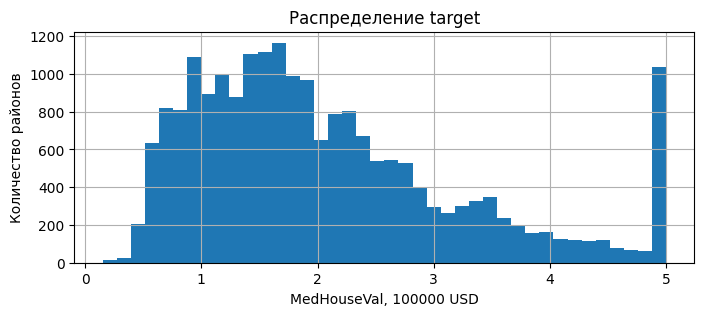

In [7]:
ax = frame[TARGET].hist(bins=40, figsize=(8, 3))
ax.set(
    xlabel="MedHouseVal, 100000 USD",
    ylabel="Количество районов",
    title="Распределение target",
)
plt.show()

<a id="baseline"></a>

## Baseline

Прежде чем обучать полезную модель, реализуй правила оценки. **Baseline** — точка отсчёта: `DummyRegressor(strategy="mean")` предсказывает среднее target только обучающей выборки. Для train `[1, 2, 9]` прогноз равен `4`, а не медиане `2`.

### Метрики

`regression_metrics(y_true, y_pred) -> dict[str, float]` принимает одинаковые непустые одномерные конечные массивы, иначе поднимает `ValueError`. Возвращает ровно `mae` и `rmse` в единицах target.

MAE — среднее абсолютное отклонение; RMSE — корень из среднего квадрата отклонений. Для `[0, 2]` против `[0, 0]` MAE = 1, RMSE = √2. Эта разница помогает заметить случайное использование одной формулы дважды. Подробнее: [метрики и baseline](README.md#baseline-и-метрики).


In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def regression_metrics(y_true, y_pred) -> dict[str, float]:
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if len(y_true) == 0 or len(y_pred) == 0:
        raise ValueError
    if len(y_true) != len(y_pred):
        raise ValueError
    if y_true.ndim > 1 or y_pred.ndim > 1:
        raise ValueError
    if not np.isfinite(y_true).all() or not np.isfinite(y_pred).all():
        raise ValueError
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": root_mean_squared_error(y_true, y_pred)
    }

### Проверка метрик

Проверки ниже различают MAE и RMSE, проверяют дробные числа, идеальный прогноз, пустой ввод, разные длины, размерности, NaN и ±Infinity с обеих сторон. Все ожидаемые значения вычислены независимо от учебных функций. Выполни всю ячейку: просто определить `test_*` недостаточно, вызовы уже добавлены внизу.


In [26]:
def test_metrics():
    assert regression_metrics([0, 2], [0, 0]) == {
        "mae": 1.0,
        "rmse": pytest.approx(2**0.5),
    }
    assert regression_metrics([1, 1], [1, 1]) == {"mae": 0.0, "rmse": 0.0}


test_metrics()


def test_invalid_metrics(a, b):
    with pytest.raises(ValueError):
        regression_metrics(a, b)


for a, b in [
    ([], []),
    ([1], [1, 2]),
    ([float("nan")], [0]),
    ([[1]], [[1]]),
    ([0], [float("inf")]),
]:
    test_invalid_metrics(a, b)


def test_metrics_varied_values(truth, predicted):
    errors = np.asarray(truth) - np.asarray(predicted)
    assert regression_metrics(truth, predicted) == {
        "mae": pytest.approx(np.abs(errors).mean()),
        "rmse": pytest.approx(np.sqrt(np.square(errors).mean())),
    }


for truth, predicted in [
    ([1, -2, 8], [4, -2, 0]),
    ([0.5], [-1.25]),
    ([3, 5, 9, -2], [1] * 4),
]:
    test_metrics_varied_values(truth, predicted)


def test_metrics_reject_invalid_on_either_side(bad, side):
    args = [[0], [0]]
    args[side] = bad
    with pytest.raises(ValueError):
        regression_metrics(*args)


for bad in [[float("nan")], [float("inf")], [-float("inf")], [[1, 2]], [[[1]]], 1.0]:
    for side in [0, 1]:
        test_metrics_reject_invalid_on_either_side(bad, side)

print("Проверки пройдены")

Проверки пройдены


### Разбиение

`make_split(n_rows: int, seed: int = 42) -> dict` возвращает списки исходных **позиций** строк `train`, `validation`, `test` с долями 60/20/20. Используй два вызова `train_test_split` с одним seed: сначала `test_size=0.2`, затем `test_size=0.25` от оставшихся строк. Не округляй доли самостоятельно: тесты учитывают поведение sklearn на нечётном числе строк.

Train используется для `fit`; validation — для выбора конфигурации; test — для окончательной оценки. Не вычисляй preprocessing по полной таблице: это утечка информации из оценки. Подробнее: [разбиение и утечка](README.md#разбиение-и-утечка).


In [34]:
def make_split(n_rows: int, seed: int = 42) -> dict:
    train, test = train_test_split(
        list(range(n_rows)), test_size=0.2, random_state=seed
    )
    train, validation = train_test_split(
        train, test_size=0.25, random_state=seed
    )
    return {
        "train": train,
        "test": test,
        "validation": validation 
    }

### Проверка split

На 100 строках ожидаются 60/20/20. Важны не только размеры: проверяем точные позиции, повторяемость и округление для разных размеров и seed.


In [35]:
def test_split_exact_and_deterministic():
    part = make_split(100, 42)
    trainval, test = train_test_split(list(range(100)), test_size=0.2, random_state=42)
    train, valid = train_test_split(trainval, test_size=0.25, random_state=42)
    assert part == {"train": list(train), "validation": list(valid), "test": list(test)}
    assert part == make_split(100, 42)


test_split_exact_and_deterministic()


def test_split_rounding_and_seeds(n, seed):
    trainval, test = train_test_split(list(range(n)), test_size=0.2, random_state=seed)
    train, valid = train_test_split(trainval, test_size=0.25, random_state=seed)
    expected = {"train": list(train), "validation": list(valid), "test": list(test)}
    assert make_split(n, seed) == expected
    assert make_split(n, seed) == expected


for n, seed in [(5, 0), (7, 17), (11, 42), (23, 9), (101, 3)]:
    test_split_rounding_and_seeds(n, seed)

print("Проверки пройдены")

Проверки пройдены


### Постоянный прогноз

`fit_baseline(frame, split: dict) -> dict` проверяет состав столбцов: ровно `FEATURES + [TARGET]`. Обучи `DummyRegressor(mean)` только на train и верни `validation`/`test` с `mae`/`rmse`. Не изменяй разбиение ради улучшения метрик.

Для train `[1, 2, 9]`, validation `[100]` и test `[20, 40]` правильны validation MAE 96, test MAE 26, test RMSE √776. Нестандартные метки DataFrame не должны менять позиционное разбиение.


In [ ]:
def fit_baseline(frame, split: dict) -> dict:
    expected_columns = set(FEATURES + [TARGET])

    if set(frame.columns) != expected_columns:
        raise ValueError("В таблице должны быть ровно FEATURES и TARGET")

    if not frame.columns.is_unique or set(frame.columns) != expected_columns:
        raise ValueError("В таблице должны быть ровно FEATURES и TARGET")
    
    regressor = DummyRegressor(strategy="mean")

    train = frame.iloc[split["train"]]
    validation = frame.iloc[split["validation"]]
    test = frame.iloc[split["test"]]

    X_train = train[FEATURES]
    y_train = train[TARGET]

    regressor.fit(X_train, y_train)

    test_pred = regressor.predict(test[FEATURES])
    validation_pred = regressor.predict(validation[FEATURES])
    return {
        "test": regression_metrics(test[TARGET], test_pred),
        "validation": regression_metrics(validation[TARGET], validation_pred)   
    }

### Проверка baseline

Проверяем отсутствие утечки, среднее вместо медианы, обращение по позициям и отказ при отсутствующем либо лишнем столбце.


In [50]:
def test_baseline_uses_train_only():
    f = pd.DataFrame({name: [1.0, 2.0, 3.0, 4.0, 5.0] for name in FEATURES})
    f[TARGET] = [1.0, 3.0, 100.0, 20.0, 40.0]
    p = {"train": [0, 1], "validation": [2], "test": [3, 4]}
    result = fit_baseline(f, p)
    assert result["validation"]["mae"] == 98.0
    assert result["test"]["mae"] == 28.0
    with pytest.raises(ValueError):
        fit_baseline(f.assign(unexpected=1), p)


test_baseline_uses_train_only()


def test_baseline_uses_positions_and_asymmetric_train_mean():
    frame = pd.DataFrame(
        {name: list(range(6)) for name in FEATURES}, index=[90, 10, 80, 20, 70, 30]
    )
    frame[TARGET] = [1.0, 2.0, 9.0, 100.0, 20.0, 40.0]
    split = {"train": [0, 1, 2], "validation": [3], "test": [4, 5]}
    result = fit_baseline(frame, split)
    assert result["validation"] == {"mae": 96.0, "rmse": 96.0}
    assert result["test"] == {"mae": 26.0, "rmse": pytest.approx(776**0.5)}
    for column in FEATURES + [TARGET]:
        with pytest.raises(ValueError):
            fit_baseline(frame.drop(columns=column), split)


test_baseline_uses_positions_and_asymmetric_train_mean()

print("Проверки пройдены")

Проверки пройдены


In [51]:
split = make_split(len(frame), SEED)
baseline_metrics = fit_baseline(frame, split)
pd.DataFrame(baseline_metrics).T

,mae,rmse
test,0.905296,1.144806
validation,0.924793,1.171903


<a id="кандидат"></a>

## Кандидат

Теперь нужна модель, использующая признаки. `Pipeline` объединяет preprocessing и estimator: при `fit` обучаются все шаги, при `predict` повторяется та же обработка. Если сохранить только estimator, API может получить иной прогноз из-за потерянного scaler или порядка признаков. Подробнее: [Pipeline](README.md#pipeline-и-модели).

### Построение Pipeline

`build_pipeline(seed: int = 42) -> sklearn.pipeline.Pipeline` возвращает необученный Pipeline с обработкой признаков и регрессором из scikit-learn. Импорты `SimpleImputer`, `StandardScaler`, `Ridge`, `RandomForestRegressor` подготовлены. Для случайного алгоритма зафиксируй seed.


In [69]:
def build_pipeline(seed: int = 42) -> Pipeline:
    return Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ])

def build_pipeline2(seed: int = 42) -> Pipeline:
    return Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("model", RandomForestRegressor(random_state=seed))
    ])

### Проверка Pipeline

Маленькая синтетическая таблица проверяет обучение, форму прогнозов, конечность и сохранение/загрузку всего Pipeline. Она не заменяет проверку качества на housing.


In [58]:
def test_pipeline_fits_and_roundtrips(tmp_path):
    rng = np.random.default_rng(42)
    X = pd.DataFrame(rng.normal(size=(80, 8)), columns=FEATURES)
    y = 2 * X["MedInc"] + X["Latitude"]
    p = build_pipeline(42)
    assert isinstance(p, Pipeline)
    p.fit(X.iloc[:60], y.iloc[:60])
    pred = p.predict(X.iloc[60:])
    assert pred.shape == (20,) and np.isfinite(pred).all()
    joblib.dump(p, tmp_path / "p.joblib")
    assert np.allclose(pred, joblib.load(tmp_path / "p.joblib").predict(X.iloc[60:]))


with TemporaryDirectory() as directory:
    tmp_path = Path(directory)
    test_pipeline_fits_and_roundtrips(tmp_path)

print("Проверки пройдены")

Проверки пройдены


/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [59]:
rng = np.random.default_rng(42)
x = pd.DataFrame(rng.normal(size=(40, len(FEATURES))), columns=FEATURES)
y = 2 * x["MedInc"] + 1
pipeline_for_check = build_pipeline(seed=42)
pipeline_for_check.fit(x, y)
predictions_for_check = pipeline_for_check.predict(x.iloc[:3])
assert predictions_for_check.shape == (3,)
assert np.isfinite(predictions_for_check).all()
assert regression_metrics(np.array([1.0, 3.0]), np.array([1.0, 1.0])) == {
    "mae": 1.0,
    "rmse": pytest.approx(2**0.5),
}
print("Проверки формы и единиц пройдены")

Проверки формы и единиц пройдены


/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


### Программа обучения

`train(data: Path, output: Path, seed: int) -> None` читает CSV и выполняет весь повторяемый эксперимент. Она нужна не только notebook: Airflow и ClearML будут вызывать её без интерактивного ядра. Не используй в ней глобальные `frame`, `DATA`, `split` или результаты ранее выполненных ячеек.

Требуется:

1. Получить split через `make_split`; посчитать baseline через `fit_baseline`.
2. На одном split сравнить Dummy, Ridge и небольшой RandomForest. Preprocessing обучать только на train, конфигурацию выбирать по validation.
3. Зафиксировать выбор и один раз оценить выбранного кандидата на test.
4. В `output` сохранить четыре файла из таблицы ниже. Полную модель сериализовать с preprocessing; модель заменять атомарно, при ошибке сериализации сохранять прежний активный файл.

| Файл | Контракт |
|---|---|
| `model.joblib` | Bundle: `schema_version=1`, обученный `pipeline`, `features=FEATURES`, непустой `model_version` |
| `metrics.json` | `baseline` и `candidate`, у каждого `validation` и `test`, внутри `mae` и `rmse` |
| `manifest.json` | `seed`, `data_sha256`, `versions`, `parameters`, `feature_order`, `split` |
| `split.json` | Исходные позиционные индексы `train`, `validation`, `test` |

SHA-256 относится к исходным bytes CSV, `manifest.split` совпадает с `split.json`. Метрики должны соответствовать сохранённому Pipeline и тем же строкам. На полном housing ожидается `candidate.test.mae <= 0.9 * baseline.test.mae`. Если порог не достигнут, не используй test для повторного подбора; исследование и выбор конфигурации проводи на train/validation.

Одинаковые данные и seed дают одинаковый split и близкие прогнозы. Версии библиотек также являются частью воспроизводимости. [Подробный контракт](../../labs/housing/README.md).


In [73]:
from tempfile import TemporaryDirectory

def fit_baseline2(frame, split: dict, arg: str, seed: int = 42) -> tuple:
    match arg:
        case "tree":
            model = build_pipeline2(seed)
        case "ridge":
            model = build_pipeline(seed)
        case "dummy":
            model = DummyRegressor(strategy="mean")
        case _:
            raise ValueError(f"Неизвестная модель: {arg}")

    train = frame.iloc[split["train"]]
    validation = frame.iloc[split["validation"]]

    model.fit(train[FEATURES], train[TARGET])

    validation_pred = model.predict(validation[FEATURES])
    metrics = regression_metrics(validation[TARGET], validation_pred)

    return model, metrics



In [76]:
def train(data: Path, output: Path, seed: int) -> None:
    frame = pd.read_csv(data)
    split = make_split(len(frame), seed=seed) ##############

    dummy, res_dummy = fit_baseline2(frame, split, "dummy", seed)
    ridge, res_ridge = fit_baseline2(frame, split, "ridge", seed)
    forest, res_forest = fit_baseline2(frame, split, "tree", seed)

    if res_ridge["mae"] <= res_forest["mae"]:
        best_model = ridge
        best_validation_metrics = res_ridge
    else:
        best_model = forest
        best_validation_metrics = res_forest

    test = frame.iloc[split["test"]]

    dummy_pred = dummy.predict(test[FEATURES])
    best_pred = best_model.predict(test[FEATURES])

    dummy_test = regression_metrics(test[TARGET], dummy_pred)
    best_test = regression_metrics(test[TARGET], best_pred)
    metrics = {
        "baseline": {"validation": res_dummy, "test": dummy_test},
        "candidate": {"validation": best_validation_metrics, "test": best_test},
    }

    bundle = {
        "schema_version": 1,
        "pipeline": best_model,
        "features": FEATURES,
        "model_version": "1.0",
    }

    manifest = {
        "seed": seed,
        "data_sha256": hashlib.sha256(data.read_bytes()).hexdigest(),
        "versions": {
            "pandas": pd.__version__,
            "sklearn": sklearn.__version__,
        },
        "parameters": {
            "model": best_model.named_steps["model"].get_params(),
        },
        "feature_order": FEATURES,
        "split": split,
    }

    output.mkdir(parents=True, exist_ok=True)

    with TemporaryDirectory(dir=output.parent) as directory:
        staging = Path(directory)

        # Сначала сохраняем все файлы во временную папку.
        for name, value in [
            ("metrics.json", metrics),
            ("manifest.json", manifest),
            ("split.json", split),
        ]:
            (staging / name).write_text(
                json.dumps(value, indent=2, ensure_ascii=False),
                encoding="utf-8",
            )

        joblib.dump(bundle, staging / "model.joblib")

        # Если сохранение прошло успешно, переносим файлы в output.
        for name in [
            "metrics.json",
            "manifest.json",
            "split.json",
            "model.joblib",
        ]:
            (staging / name).replace(output / name)


def main() -> None:
    # Готовый вход для python -m housing.train; при импорте не вызывается.
    parser = argparse.ArgumentParser()
    parser.add_argument("--data", type=Path, required=True)
    parser.add_argument("--output", type=Path, required=True)
    parser.add_argument("--seed", type=int, default=42)
    args = parser.parse_args()
    train(args.data, args.output, args.seed)

### Проверка артефактов и повторного обучения

Проверяются четыре согласованных файла, независимый пересчёт метрик сохранённой модели на её split, SHA-256 и повторяемость. Затем искусственная ошибка сериализации должна оставить предыдущую модель читаемой и неизменной. Временные папки и подмена сериализатора очищаются даже при падении проверки.


In [77]:
def test_training_artifacts_and_repeat(tmp_path):
    rng = np.random.default_rng(7)
    frame = pd.DataFrame(rng.uniform(1, 3, (100, 8)), columns=FEATURES)
    frame[TARGET] = 2 * frame.MedInc + frame.Latitude
    path = tmp_path / "input.csv"
    frame.to_csv(path, index=False)
    outputs = [tmp_path / "one", tmp_path / "two"]
    predictions = []
    for out in outputs:
        train(path, out, 42)
        bundle = joblib.load(out / "model.joblib")
        assert bundle["schema_version"] == 1 and bundle["features"] == FEATURES
        assert isinstance(bundle["model_version"], str) and bundle["model_version"]
        predictions.append(bundle["pipeline"].predict(frame[FEATURES].iloc[:20]))
        metrics = read_json(out / "metrics.json")
        for model in ["baseline", "candidate"]:
            for part in ["validation", "test"]:
                assert set(metrics[model][part]) == {"mae", "rmse"}
                assert all(
                    (np.isfinite(v) and v >= 0 for v in metrics[model][part].values())
                )
        manifest = read_json(out / "manifest.json")
        assert manifest["data_sha256"] == hashlib.sha256(path.read_bytes()).hexdigest()
        assert manifest["seed"] == 42 and manifest["feature_order"] == FEATURES
        assert manifest["versions"] and manifest["parameters"]
        split = read_json(out / "split.json")
        assert manifest["split"] == split
        assert sorted(sum(split.values(), [])) == list(range(100))
        for part in ["validation", "test"]:
            positions = split[part]
            truth = frame[TARGET].iloc[positions].to_numpy()
            predictions_for_part = bundle["pipeline"].predict(
                frame[FEATURES].iloc[positions]
            )
            baseline_mean = frame[TARGET].iloc[split["train"]].mean()
            for model, predicted in [
                ("candidate", predictions_for_part),
                ("baseline", np.full(len(positions), baseline_mean)),
            ]:
                errors = truth - predicted
                assert metrics[model][part] == {
                    "mae": pytest.approx(np.abs(errors).mean()),
                    "rmse": pytest.approx(np.sqrt(np.square(errors).mean())),
                }
        assert all(
            (
                (out / name).stat().st_size > 0
                for name in [
                    "model.joblib",
                    "metrics.json",
                    "manifest.json",
                    "split.json",
                ]
            )
        )
    assert read_json(outputs[0] / "split.json") == read_json(outputs[1] / "split.json")
    assert np.allclose(*predictions, rtol=1e-06, atol=1e-08)


with TemporaryDirectory() as directory:
    tmp_path = Path(directory)
    test_training_artifacts_and_repeat(tmp_path)


def test_failed_model_serialization_preserves_previous_model(tmp_path, monkeypatch):
    rng = np.random.default_rng(71)
    frame = pd.DataFrame(rng.normal(size=(40, len(FEATURES))), columns=FEATURES)
    frame[TARGET] = frame.MedInc * 2 + frame.Latitude
    data = tmp_path / "input.csv"
    frame.to_csv(data, index=False)
    output = tmp_path / "active"
    train(data, output, 42)
    model = output / "model.joblib"
    previous_bytes = model.read_bytes()
    previous_predictions = joblib.load(model)["pipeline"].predict(frame[FEATURES])
    serialization_attempts = []

    def failing_state(self):
        serialization_attempts.append(self)
        raise OSError("simulated serialization failure")

    monkeypatch.setattr(Pipeline, "__getstate__", failing_state)
    with pytest.raises(Exception) as failure:
        train(data, output, 7)
    assert serialization_attempts
    assert not isinstance(failure.value, NotImplementedError)
    assert model.read_bytes() == previous_bytes
    assert np.allclose(
        joblib.load(model)["pipeline"].predict(frame[FEATURES]), previous_predictions
    )


with TemporaryDirectory() as directory:
    tmp_path = Path(directory)
    with pytest.MonkeyPatch.context() as monkeypatch:
        test_failed_model_serialization_preserves_previous_model(tmp_path, monkeypatch)

print("Проверки пройдены")

Проверки пройдены


### Полный эксперимент

Запусти эту ячейку после прохождения маленьких проверок. Обучение временно записывает комплект в изолированную папку; он загружается в память, папка удаляется. Рабочая модель в `work/artifacts/` здесь не меняется: публикация будет последним действием notebook.

После этого конфигурация зафиксирована. Не подбирай её по увиденному test. Произвольные числа из примеров курса не заменяют собственные метрики.


In [78]:
with TemporaryDirectory() as directory:
    run_dir = Path(directory)
    train(DATA, run_dir, SEED)
    bundle = joblib.load(run_dir / "model.joblib")
    metrics = read_json(run_dir / "metrics.json")
    manifest = read_json(run_dir / "manifest.json")
    split = read_json(run_dir / "split.json")

comparison = pd.DataFrame(
    {
        name: {
            f"{part}_{metric}": value
            for part, values in result.items()
            for metric, value in values.items()
        }
        for name, result in metrics.items()
    }
).T
comparison

/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/yaroslav/Desktop/MLops-course/.venv/lib/python3.12/site-packages/sklearn/linear_model/_base.py:279: Runti

,validation_mae,validation_rmse,test_mae,test_rmse
baseline,0.924793,1.171903,0.905296,1.144806
candidate,0.335282,0.509593,0.331553,0.508978


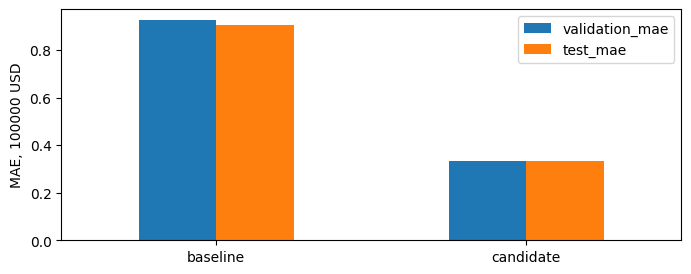

In [79]:
assert manifest["split"] == split
assert manifest["feature_order"] == bundle["features"] == FEATURES
assert metrics["candidate"]["test"]["mae"] <= 0.9 * metrics["baseline"]["test"]["mae"]
comparison[["validation_mae", "test_mae"]].plot.bar(
    figsize=(8, 3), ylabel="MAE, 100000 USD", rot=0
)
plt.show()

<a id="анализ-ошибок"></a>

## Анализ ошибок

Общая MAE скрывает неоднородность: дорогие районы могут иметь гораздо большую ошибку. Извлеки test-строки по сохранённым позициям, затем сравни прогнозы с target тех же строк. Не соединяй независимо отсортированные массивы по позиции.

### Ошибки по квартилям

`quartile_errors(y_true, y_pred) -> list[dict]` принимает одинаковые непустые одномерные конечные массивы. Группирует по `pd.qcut(y_true, 4, labels=False, duplicates="drop")` и возвращает упорядоченные записи `quartile`, `count`, `mae`, `rmse`. Для непустых групп используются номера с 1; одинаковые targets образуют одну группу `quartile=1`. Ошибочный ввод вызывает `ValueError`.

На targets `[0,1,2,3,4,5,6,7]` с прогнозом 0 ожидаются MAE 0.5/2.5/4.5/6.5 и по два наблюдения в группе. Подробнее: [анализ групп](README.md#анализ-групп-и-неверные-успехи).


In [80]:
def quartile_errors(y_true, y_pred) -> list[dict]:
    # TODO: проверить массивы, сгруппировать по qcut и посчитать метрики каждой группы.
    raise NotImplementedError("Проанализируй ошибки")

### Проверка групп

Проверки охватывают MAE/RMSE всех групп, одинаковые и повторяющиеся targets, неравномерные группы и некорректные массивы.


In [81]:
def test_quartiles_and_counts():
    rows = quartile_errors(list(range(8)), [0] * 8)
    assert [r["quartile"] for r in rows] == [1, 2, 3, 4]
    assert [r["count"] for r in rows] == [2] * 4
    assert [r["mae"] for r in rows] == [0.5, 2.5, 4.5, 6.5]
    assert [r["rmse"] for r in rows] == pytest.approx(
        [0.5**0.5, 6.5**0.5, 20.5**0.5, 42.5**0.5]
    )
    assert quartile_errors([2, 2], [1, 3]) == [
        {"quartile": 1, "count": 2, "mae": 1.0, "rmse": 1.0}
    ]


test_quartiles_and_counts()


def test_quartile_metrics_uneven_groups_and_ties(truth, predicted, groups):
    result = quartile_errors(truth, predicted)
    assert len(result) == len(groups)
    for quartile, (row, positions) in enumerate(zip(result, groups), start=1):
        errors = np.asarray(truth)[positions] - np.asarray(predicted)[positions]
        assert row == {
            "quartile": quartile,
            "count": len(positions),
            "mae": pytest.approx(np.abs(errors).mean()),
            "rmse": pytest.approx(np.sqrt(np.square(errors).mean())),
        }


for truth, predicted, groups in [
    ([0, 1, 2, 3, 4, 5, 6], [2, 1, 0, 4, 8, 3, 9], [[0, 1], [2, 3], [4], [5, 6]]),
    ([0, 0, 0, 1, 2, 3, 3, 3], [1, 2, 3, 1, 0, 4, 5, 6], [[0, 1, 2, 3], [4, 5, 6, 7]]),
]:
    test_quartile_metrics_uneven_groups_and_ties(truth, predicted, groups)


def test_quartiles_reject_invalid_arrays(truth, predicted):
    with pytest.raises(ValueError):
        quartile_errors(truth, predicted)


for truth, predicted in [
    ([], []),
    ([[1]], [[1]]),
    ([float("inf")], [1]),
    ([1], [float("nan")]),
    ([1, 2], [1]),
]:
    test_quartiles_reject_invalid_arrays(truth, predicted)

print("Проверки пройдены")

NotImplementedError: Проанализируй ошибки

In [ ]:
test_rows = frame.iloc[split["test"]]
y_true = test_rows[TARGET].to_numpy()
y_pred = bundle["pipeline"].predict(test_rows[FEATURES])
errors_by_quartile = pd.DataFrame(quartile_errors(y_true, y_pred))
errors_by_quartile

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].scatter(y_true, y_pred, s=4, alpha=0.25)
axes[0].set(
    xlabel="Target, 100000 USD",
    ylabel="Прогноз, 100000 USD",
    title="Прогноз против ответа",
)
axes[1].hist(y_true - y_pred, bins=40)
axes[1].set(xlabel="Ответ − прогноз, 100000 USD", ylabel="Количество", title="Остатки")
plt.tight_layout()
plt.show()

### Географическое разбиение

Случайное перемешивание не показывает перенос в новый регион. `geographic_split(frame, latitude_cutoff: float) -> dict` делит **исходные метки индекса** на `train` (`Latitude < cutoff`) и `test` (`>= cutoff`), сохраняя порядок. Пустая сторона вызывает `ValueError`. Для широт `[33,35,36]`, индекса `[10,20,30]` и границы 35 ожидаются train `[10]`, test `[20,30]`.

Это отдельный опыт: географическая модель не заменяет уже выбранный рабочий bundle. Для подбора внутри северной/южной обучающей части выдели собственную validation, не используй географический test для выбора.


In [ ]:
def geographic_split(frame, latitude_cutoff: float) -> dict:
    # TODO: вернуть исходные метки обеих сторон, проверить непустоту.
    raise NotImplementedError("Раздели регионы")

### Проверка географической границы

Равенство границе относится к test. Проверяются произвольные метки, порядок и обе пустые стороны. Комбинированный тест также сохраняет проверку несовпадения длин для квартилей.


In [ ]:
def test_geographic_boundary_and_validation():
    f = pd.DataFrame({"Latitude": [33.0, 35.0, 36.0]}, index=[10, 20, 30])
    assert geographic_split(f, 35.0) == {"train": [10], "test": [20, 30]}
    with pytest.raises(ValueError):
        geographic_split(f, 40.0)
    with pytest.raises(ValueError):
        quartile_errors([1, 2], [1])


test_geographic_boundary_and_validation()


def test_geographic_order_and_both_empty_sides():
    frame = pd.DataFrame(
        {"Latitude": [35.0, 34.9, 35.1, 30.0]}, index=["d", "a", "c", "b"]
    )
    assert geographic_split(frame, 35.0) == {"train": ["a", "b"], "test": ["d", "c"]}
    for cutoff in [30.0, 36.0]:
        with pytest.raises(ValueError):
            geographic_split(frame, cutoff)


test_geographic_order_and_both_empty_sides()

print("Проверки пройдены")

### Самостоятельные опыты

1. Обучи отдельный Pipeline на географическом train, оцени на географическом test и сопоставь результат со случайным разбиением. Применяй метки через `.loc`; не перезаписывай `bundle`, `metrics`, `manifest`, `split` основного запуска.
2. На отдельной копии эксперимента намеренно выполни scaler-fit до split и сравни метрики с корректным Pipeline. Даже небольшая разница не оправдывает утечку: нарушение определяется доступом к данным, а не размером улучшения. Этот артефакт не сохраняй как рабочий.

Здесь нужны вычисления и графики, письменный отчёт не требуется. Готовых реализаций этих опытов нет.


In [ ]:
# TODO: отдельный географический опыт; используй собственные переменные geo_*.
# TODO: отдельный ошибочный опыт со scaler до split; используй переменные leaked_*.
# Основной bundle после этих опытов остаётся неизменным.


<a id="сохранение-результата"></a>

## Сохранение результата

Последняя ячейка готова: она **не обучает** модель, а сохраняет находящиеся в памяти `bundle`, `metrics`, `manifest`, `split` непосредственно в `work/artifacts/`. Сначала весь комплект сериализуется во временную папку. `export_files` проверяет файлы и конфликты, затем заменяет каждый файл атомарно; модель — последней. Весь комплект не является единой транзакцией.

При существующем отличающемся результате функция откажется заменять его. После осознанного выбора используй `replace=True` в последнем вызове. Посторонние файлы не удаляются. Если API уже работает, после замены модели его нужно перезапустить.

Результат — `model.joblib`, `metrics.json`, `manifest.json`, `split.json`. Каталог `work/` исключён из Git, а notebook с твоим кодом можно сохранить в репозитории. Перед коммитом очисти результаты выполнения и проверь отсутствие личных данных. Следующие модули читают эти файлы; повторное обучение запускается через `python -m housing.train --data work/housing.csv --output work/runs/example --seed 42` и использует сохранённые определения этого notebook.


In [82]:
def save_artifacts(bundle, metrics, manifest, split, *, replace=False):
    """Сохранить подготовленный комплект; обучение и тесты не запускаются."""
    destination = course_root() / "work/artifacts"
    with TemporaryDirectory() as directory:
        staging = Path(directory)
        for name, value in [
            ("metrics.json", metrics),
            ("manifest.json", manifest),
            ("split.json", split),
        ]:
            (staging / name).write_text(
                json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
                encoding="utf-8",
            )
        joblib.dump(bundle, staging / "model.joblib")
        names = ["metrics.json", "manifest.json", "split.json", "model.joblib"]
        try:
            changed = export_files(
                [(staging / name, destination / name) for name in names],
                replace=replace,
            )
        except FileExistsError as error:
            raise FileExistsError(
                str(error).replace("--replace", "replace=True")
            ) from error
    for name in names:
        print(destination / name)
    print("Сохранено" if changed else "Файлы уже совпадают")
    return changed


save_artifacts(bundle, metrics, manifest, split)

/Users/yaroslav/Desktop/MLops-course/work/artifacts/metrics.json
/Users/yaroslav/Desktop/MLops-course/work/artifacts/manifest.json
/Users/yaroslav/Desktop/MLops-course/work/artifacts/split.json
/Users/yaroslav/Desktop/MLops-course/work/artifacts/model.joblib
Сохранено


[PosixPath('/Users/yaroslav/Desktop/MLops-course/work/artifacts/metrics.json'),
 PosixPath('/Users/yaroslav/Desktop/MLops-course/work/artifacts/manifest.json'),
 PosixPath('/Users/yaroslav/Desktop/MLops-course/work/artifacts/split.json'),
 PosixPath('/Users/yaroslav/Desktop/MLops-course/work/artifacts/model.joblib')]